# 01. What is in the series

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160, "display.max_columns", 40)
data, weather_fc = load_data()
y = data["y"].to_numpy(float)
FEATURES = [c for c in weather_fc.columns if c != "ds"]
print(len(data), "hours, last one:", data["ds"].iloc[-1])

33480 hours, last one: 2026-10-27 00:00:00


## Level over time

We look at the monthly mean first, because a growing level decides how much history a model may use.

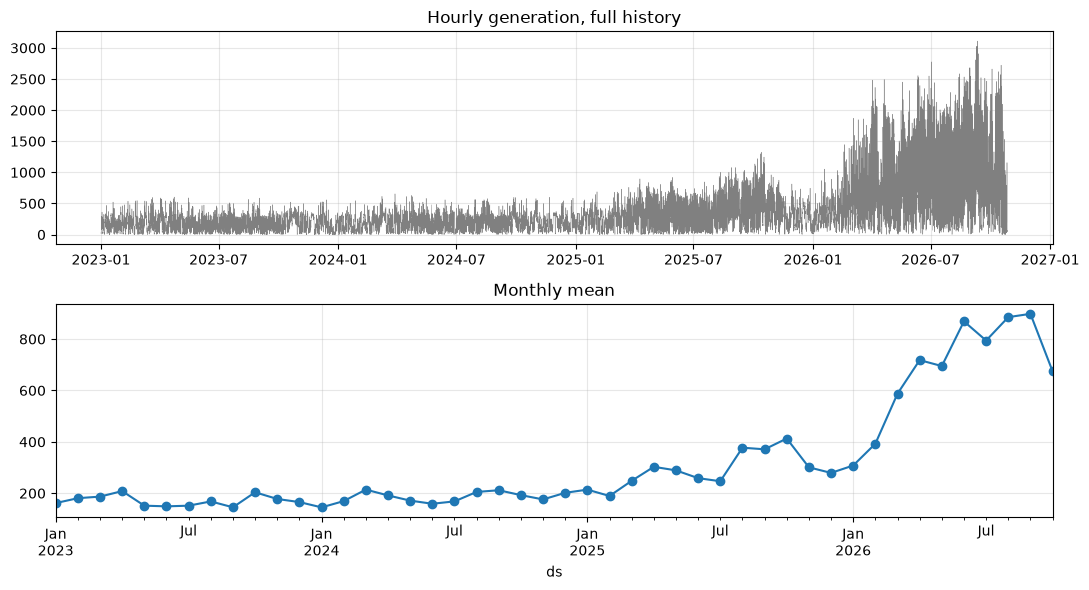

ds
2023    171.0
2024    184.0
2025    291.0
2026    682.0


In [2]:
monthly = data.set_index("ds")["y"].resample("ME").mean()
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(data["ds"], y, lw=0.3, color="grey"); ax[0].set_title("Hourly generation, full history")
monthly.plot(ax=ax[1], marker="o", title="Monthly mean")
plt.tight_layout(); plt.show()
print(monthly.groupby(monthly.index.year).mean().round(0).to_string())

## Daily shape and day-to-day change

The benchmark copies one day, so what matters is how much one day differs from the next.

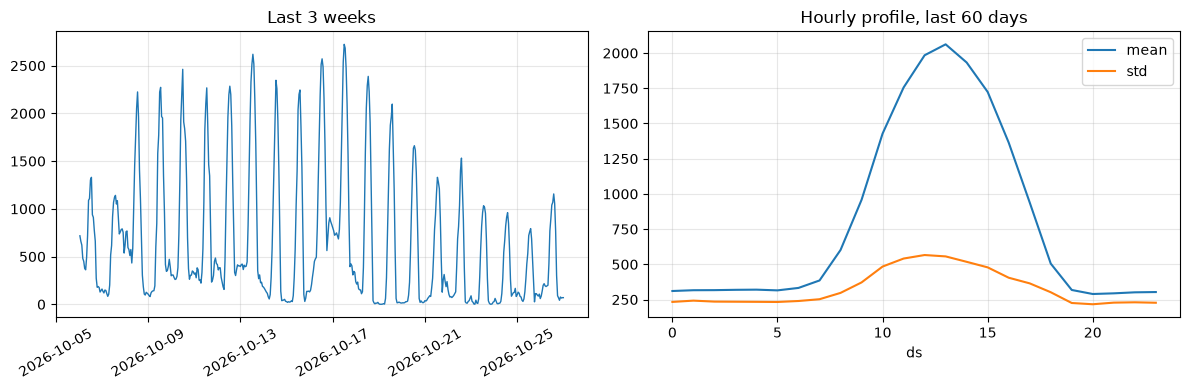

daily peaks, last 14 days:
ds
2026-10-13    2619.0
2026-10-14    2347.0
2026-10-15    2245.0
2026-10-16    2572.0
2026-10-17    2724.0
2026-10-18    2388.0
2026-10-19    2098.0
2026-10-20    1662.0
2026-10-21    1330.0
2026-10-22    1532.0
2026-10-23    1033.0
2026-10-24     960.0
2026-10-25     793.0
2026-10-26    1156.0
2026-10-27      70.0
Freq: D


In [3]:
recent = data.tail(60 * 24)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
last = data.tail(21 * 24)
ax[0].plot(last["ds"], last["y"], lw=1); ax[0].set_title("Last 3 weeks"); ax[0].tick_params(axis="x", rotation=30)
recent.groupby(recent["ds"].dt.hour)["y"].agg(["mean", "std"]).plot(ax=ax[1], title="Hourly profile, last 60 days")
plt.tight_layout(); plt.show()

peaks = data.tail(14 * 24).set_index("ds")["y"].resample("D").max().round(0)
print("daily peaks, last 14 days:"); print(peaks.to_string())

## Decomposition

MSTL splits the last 60 days into trend, daily and weekly parts, so we can see whether a weekly cycle is worth modelling.

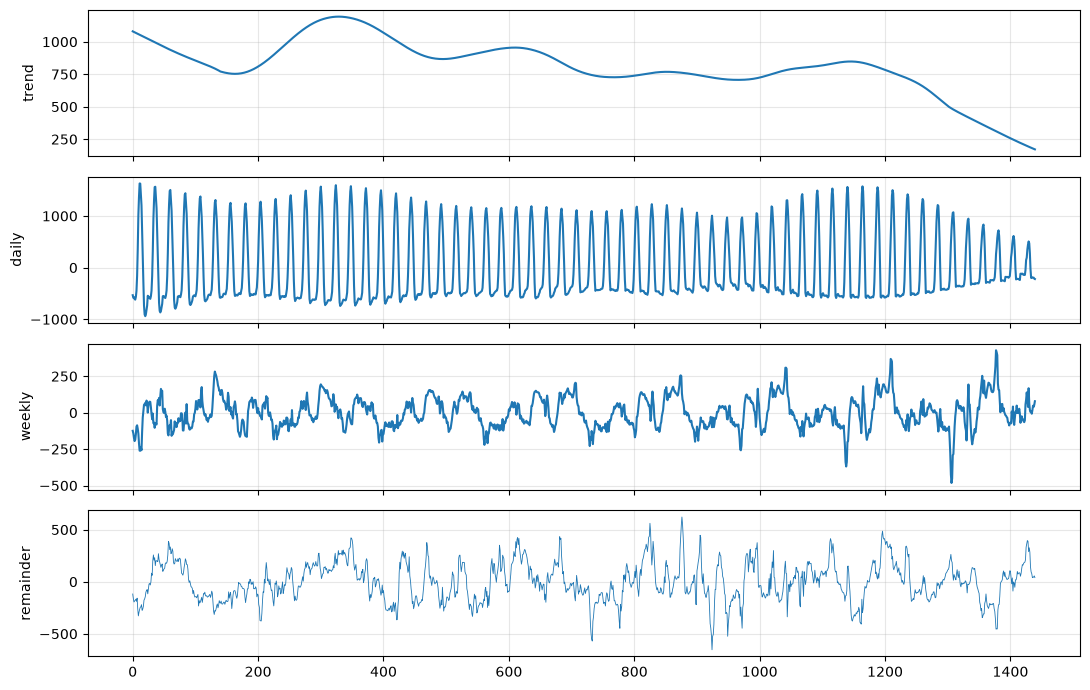

sd of parts: {'daily': 659, 'weekly': 106, 'remainder': 184}


In [4]:
from statsmodels.tsa.seasonal import MSTL

parts = MSTL(recent["y"].to_numpy(), periods=(24, 168)).fit()
fig, ax = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
ax[0].plot(parts.trend); ax[0].set_ylabel("trend")
ax[1].plot(parts.seasonal[:, 0]); ax[1].set_ylabel("daily")
ax[2].plot(parts.seasonal[:, 1]); ax[2].set_ylabel("weekly")
ax[3].plot(parts.resid, lw=0.6); ax[3].set_ylabel("remainder")
plt.tight_layout(); plt.show()
print("sd of parts:", {"daily": round(parts.seasonal[:, 0].std()), "weekly": round(parts.seasonal[:, 1].std()),
                       "remainder": round(parts.resid.std())})

## Weather

We check the sign of each relation in the data and do not assume it from the column's name.

In [5]:
print(recent.drop(columns="ds").corr()["y"].round(2).sort_values().to_string())

midday = data.tail(120 * 24)
midday = midday[midday["ds"].dt.hour.between(10, 15)].copy()
midday["temp_band"] = pd.cut(midday["temperature"], [-50, 12, 18, 60], labels=["<12", "12-18", ">18"])
print("\nmean midday y, then the number of hours behind it:")
print(midday.pivot_table(index="temp_band", columns="cloud_cover", values="y", aggfunc="mean", observed=False).round(0).to_string())
print(midday.pivot_table(index="temp_band", columns="cloud_cover", values="y", aggfunc="count", observed=False).to_string())

humidity      -0.59
air_density   -0.50
pressure       0.03
cloud_cover    0.19
temperature    0.54
wind_speed     0.58
daylight       0.74
y              1.00

mean midday y, then the number of hours behind it:
cloud_cover    0.00    0.25    0.50    0.75    1.00
temp_band                                          
<12           808.0  1035.0  1438.0     NaN  1655.0
12-18        1916.0  1524.0  1425.0     NaN  1903.0
>18          1045.0  1664.0  1724.0  1554.0  1986.0
cloud_cover  0.00  0.25  0.50  0.75  1.00
temp_band                                
<12            21    21     6     0     8
12-18           3    53    11     0    40
>18             1    54    41     2   459


## Autocorrelation

High autocorrelation at a short lag means recent errors carry information. At lag 48 it shows how far that information reaches.

In [6]:
s = pd.Series(y[-60 * 24:])
print({lag: round(s.autocorr(lag), 2) for lag in [1, 2, 24, 48, 168]})

{1: np.float64(0.95), 2: np.float64(0.81), 24: np.float64(0.91), 48: np.float64(0.88), 168: np.float64(0.79)}


## The weather forecast for the horizon

We compare it with recent actual weather, to see whether its scale matches and what kind of days are coming.

In [7]:
print(pd.DataFrame({"last 14 days": data[FEATURES].tail(14 * 24).mean(), "weather_fc": weather_fc[FEATURES].mean()}).round(2).to_string())
print(); print(weather_fc.iloc[::6][["ds", "cloud_cover", "temperature", "wind_speed", "humidity"]].to_string(index=False))

             last 14 days  weather_fc
cloud_cover          0.49        0.61
temperature         12.50        9.04
wind_speed           2.18        2.56
pressure           762.62      760.50
humidity            87.73       95.83
daylight             0.39        0.38
air_density          1.24        1.26

                 ds  cloud_cover  temperature  wind_speed  humidity
2026-10-27 01:00:00         1.00            8           4       100
2026-10-27 07:00:00         1.00            7           3       100
2026-10-27 13:00:00         1.00            8           3       100
2026-10-27 19:00:00         0.75            6           3       100
2026-10-28 01:00:00         1.00            9           4        94
2026-10-28 07:00:00         0.00            7           1       100
2026-10-28 13:00:00         0.50           19           4        70
2026-10-28 19:00:00         0.25           10           2        98


## What this means for the models

- **Level.** The yearly mean grew from 171 in 2023 to 684 in 2026, and the last 60 days average 808. Old history
  describes a smaller system, so the regressions use recent days only.
- **Fast level shifts.** Daily peaks were 2200-2700 in mid-October and only 800-1150 in the last days of the
  history. A fixed profile over many weeks can overshoot such a drop.
- **Seasonality.** In the last 60 days the daily part has an sd of 659, the weekly part 106, the remainder 184.
  The daily cycle is what matters; the weekly one is a small addition.
- **Weather.** Over the last 60 days `y` follows `daylight` (0.74), `wind_speed` (0.58), `temperature` (0.54) and
  `humidity` (-0.59), so weather should help where past values cannot.
- **`cloud_cover` has the opposite sign to its name.** Midday generation is higher when cover is higher, at every
  temperature band with enough hours. The reason is unknown and the series is disguised, so we use the column
  without interpreting it. Many of these hours sit in one cell: 459 of the 720 are warm and fully overcast.
- **Autocorrelation.** It is 0.91 at lag 24 and 0.88 at lag 48, which is why copying yesterday is a hard benchmark.
- **Forecast weather.** Its scale matches the history, so we use it. The horizon is colder and wetter than the last
  14 days, which is one more reason not to trust a model fitted on warmer weeks.